# Домашнее задание 2.3 — Связанные колебания и жёсткость (🟡)

Рассматриваю две одинаковые массы, соединённые с неподвижными опорами пружинами жёсткости $k_0$. Между массами находятся пружина $k_c$ и демпфер $c$.

$$
m\ddot x_1=-k_0x_1-k_c(x_1-x_2)-c(\dot x_1-\dot x_2),
$$
$$
m\ddot x_2=-k_0x_2-k_c(x_2-x_1)-c(\dot x_2-\dot x_1).
$$

Беру $m=k_0=1$, $x_1(0)=1$, $x_2(0)=0$, $v_1(0)=v_2(0)=0$. Сначала показываю биения при слабой связи, затем сравниваю RK4 и неявный метод трапеций при сильной связи с демпфированием. Отдельно проверяю возможность увеличить шаг после начального переходного процесса.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm, lu_factor, lu_solve
from scipy.optimize import brentq
from matplotlib.animation import PillowWriter
from IPython.display import Image, display

plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 1. Модель и точное решение

Состояние $y=(x_1,x_2,v_1,v_2)^T$ удовлетворяет линейной системе $y'=Ay$. Все параметры далее безразмерные. Ввожу среднее и относительное смещения

$$
q=\frac{x_1+x_2}{2},\qquad r=x_1-x_2.
$$

Сложение и вычитание исходных уравнений дают

$$
\ddot q+\frac{k_0}{m}q=0,\qquad
\ddot r+\frac{2c}{m}\dot r+\frac{k_0+2k_c}{m}r=0.
$$

Общее движение масс состоит из незатухающей синфазной моды и относительного движения, на которое действует демпфер. Спектр матрицы системы имеет вид

$$
\lambda_{1,2}=\pm i\sqrt{k_0/m},\qquad
\lambda_{3,4}=-c/m\pm\sqrt{(c/m)^2-(k_0+2k_c)/m}.
$$

В качестве эталона использую $y(t)=\exp(tA)y(0)$ с вычислением матричной экспоненты. Это решение непрерывной линейной системы с погрешностью машинной арифметики. Численные методы сравниваю в одни и те же физические моменты времени. Ошибки $q$ и $r$ измеряю отдельно, чтобы быстрое относительное движение не скрывало точность медленной моды.

Полная механическая энергия и её производная равны

$$
E=\frac m2(v_1^2+v_2^2)+\frac{k_0}{2}(x_1^2+x_2^2)
+\frac{k_c}{2}(x_1-x_2)^2,\qquad
\frac{dE}{dt}=-c(v_1-v_2)^2.
$$

При $c>0$ энергия убывает за счёт относительного движения. Энергия совместной моды остаётся постоянной.

## 2. Численные методы

Для RK4 использую четыре вычисления правой части за шаг. Неявный метод трапеций относится к семейству Адамса–Моултона и имеет второй порядок.

$$
y_{n+1}=y_n+\frac h2(Ay_n+Ay_{n+1}),\qquad
(I-hA/2)y_{n+1}=(I+hA/2)y_n.
$$

На каждом шаге решаю линейную систему. На постоянном шаге факторизацию матрицы сохраняю и использую повторно. Это полностью неявный шаг без итерационного приближения корректора.

Для скалярного уравнения $u'=\lambda u$ множители за шаг равны

$$
R_{\mathrm{RK4}}(z)=1+z+z^2/2+z^3/6+z^4/24,\qquad
R_{\mathrm{тр}}(z)=\frac{1+z/2}{1-z/2},\qquad z=h\lambda.
$$

У трапеций $|R(z)|\le1$ в левой полуплоскости, но $R(z)\to-1$ вдоль отрицательной вещественной оси при $|z|\to\infty$. Очень быстро затухающая компонента при большом шаге может менять знак и сохраняться дольше, чем в точном решении.

In [2]:
def system_matrix(kc, c, m=1.0, k0=1.0):
    """Матрица для состояния (x1, x2, v1, v2)."""
    return np.array([
        [0, 0, 1, 0],
        [0, 0, 0, 1],
        [-(k0 + kc) / m, kc / m, -c / m, c / m],
        [kc / m, -(k0 + kc) / m, c / m, -c / m],
    ], dtype=float)


def exact_solution(A, y0, times):
    """Матричная экспонента с повторным использованием шага для равномерных сеток."""
    times = np.asarray(times, dtype=float)
    if len(times) > 1 and np.allclose(np.diff(times), times[1] - times[0],
                                      rtol=1e-11, atol=1e-14):
        transfer = expm((times[1] - times[0]) * A)
        values = np.empty((len(times), 4))
        values[0] = expm(times[0] * A) @ y0
        for n in range(len(times) - 1):
            values[n + 1] = transfer @ values[n]
        return values
    return np.array([expm(t * A) @ y0 for t in times])


def integrate(A, y0, times, method):
    """RK4, трапеции или неявный Эйлер. Шаг задаётся массивом времён."""
    times = np.asarray(times, dtype=float)
    values = np.full((len(times), 4), np.nan)
    values[0] = y0
    factors = {}
    n_steps = 0
    stopped = False
    eye = np.eye(4)

    for n, h in enumerate(np.diff(times)):
        y = values[n]
        if method == "RK4":
            k1 = A @ y
            k2 = A @ (y + h * k1 / 2)
            k3 = A @ (y + h * k2 / 2)
            k4 = A @ (y + h * k3)
            next_y = y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            theta = {"Трапеции": 0.5, "Неявный Эйлер": 1.0}[method]
            # Округление ключа объединяет шаги, различающиеся только машинным шумом.
            key = round(float(h), 14)
            if key not in factors:
                factors[key] = lu_factor(eye - theta * h * A)
            rhs = y + h * (A @ y) / 2 if method == "Трапеции" else y
            next_y = lu_solve(factors[key], rhs)
        n_steps += 1
        # Явно фиксирую срыв, чтобы избежать переполнения и ложных графиков.
        if not np.isfinite(next_y).all() or np.linalg.norm(next_y, np.inf) > 1e6:
            stopped = True
            break
        values[n + 1] = next_y

    return values, {"Шагов": n_steps, "Факторизаций": len(factors),
                    "Срыв": stopped, "Вызовов RHS": (4 * n_steps if method == "RK4"
                                     else n_steps if method == "Трапеции" else 0),
                    "Решений СЛАУ": 0 if method == "RK4" else n_steps}


def time_grid(T, h):
    """Последний шаг при необходимости сокращается до T."""
    times = np.arange(int(np.floor(T / h + 1e-12)) + 1) * h
    if np.isclose(times[-1], T, rtol=0, atol=1e-12):
        times[-1] = T
    else:
        times = np.append(times, T)
    return times


def modes(values):
    return (values[:, 0] + values[:, 1]) / 2, values[:, 0] - values[:, 1]


def energy(values, kc, m=1.0, k0=1.0):
    x1, x2, v1, v2 = values.T
    return (m * (v1**2 + v2**2) / 2 + k0 * (x1**2 + x2**2) / 2
            + kc * (x1 - x2)**2 / 2)


def stability_function(z, method):
    if method == "RK4":
        return 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24
    if method == "Трапеции":
        return (1 + z / 2) / (1 - z / 2)
    if method == "Неявный Эйлер":
        return 1 / (1 - z)
    raise ValueError("Неизвестный метод")


Y0 = np.array([1.0, 0.0, 0.0, 0.0])
METHODS = ["RK4", "Трапеции"]

## 3. Слабая связь и биения

При $k_c=0.05$, $c=0$ собственные частоты равны $\omega_+=1$ и $\omega_-=\sqrt{1.1}$. Поэтому

$$
x_1=\tfrac12(\cos\omega_+t+\cos\omega_-t),\qquad
x_2=\tfrac12(\cos\omega_+t-\cos\omega_-t).
$$

Время переноса колебаний от одной массы к другой равно $\pi/(\omega_--\omega_+)\approx64.36$. Возврат огибающей занимает около $128.73$. На графике показан полный цикл биений.

Максимальная ошибка состояния RK4 при h=0.01: 1.251e-08


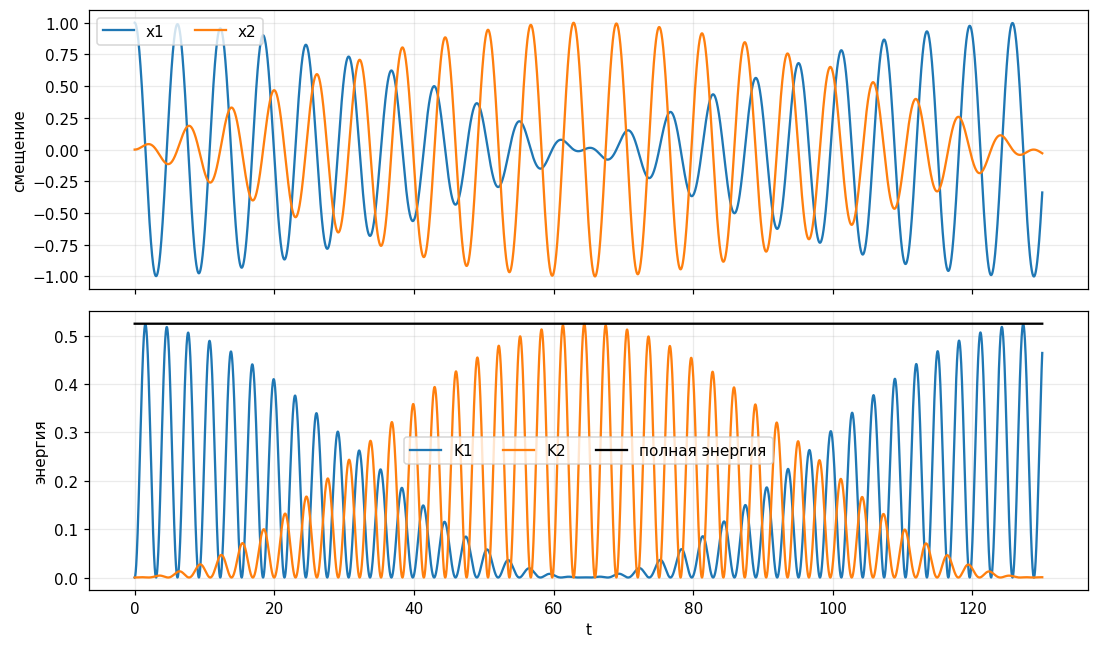

In [3]:
A_weak = system_matrix(kc=0.05, c=0)
t_weak = time_grid(130, 0.01)
weak, _ = integrate(A_weak, Y0, t_weak, "RK4")
weak_exact = exact_solution(A_weak, Y0, t_weak)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(t_weak, weak[:, 0], label="x1")
axes[0].plot(t_weak, weak[:, 1], label="x2")
axes[0].set_ylabel("смещение")
axes[0].legend(ncol=2)
axes[1].plot(t_weak, weak[:, 2]**2 / 2, label="K1")
axes[1].plot(t_weak, weak[:, 3]**2 / 2, label="K2")
axes[1].plot(t_weak, energy(weak, 0.05), color="black", label="полная энергия")
axes[1].set_ylabel("энергия")
axes[1].set_xlabel("t")
axes[1].legend(ncol=3)
fig.tight_layout()
plt.show()
print(f"Максимальная ошибка состояния RK4 при h=0.01: {np.max(abs(weak - weak_exact)):.3e}")

## 4. Сильная связь и демпфер

Выбираю $k_c=499.5$ и $c=50$. Собственная частота относительной моды без демпфера была бы $\sqrt{1000}\approx31.62$. С демпфером её два показателя затухания равны примерно $-11.27$ и $-88.73$. Это апериодический режим. За время порядка 1 относительное движение почти исчезает, а совместная мода $q(t)=0.5\cos t$ продолжает колебаться.

Сравниваю шаги $h=0.002,\ 0.02,\ 0.03$ до $T=20$. Все три шага лежат в области устойчивости RK4. Для наглядности рассматриваю отдельно первые $0.5$ единицы времени и последующее движение. Таблица измеряет ошибку на всех узлах каждого расчёта относительно точного решения на этих же узлах.

Собственные значения: [-8.87298335e+01+0.j -1.12701665e+01+0.j -1.40472522e-15-1.j
 -1.40472522e-15+1.j]


,Метод,h,max |q−q*|,max |r−r*|,Шагов
0,RK4,0.002,1.219e-12,5.117e-07,10000
1,Трапеции,0.002,3.043e-06,1.351e-04,10000
2,RK4,0.020,1.208e-08,1.633e-02,1000
3,Трапеции,0.020,3.043e-04,1.510e-02,1000
4,RK4,0.030,6.087e-08,1.105e-01,667
5,Трапеции,0.030,6.840e-04,2.814e-02,667


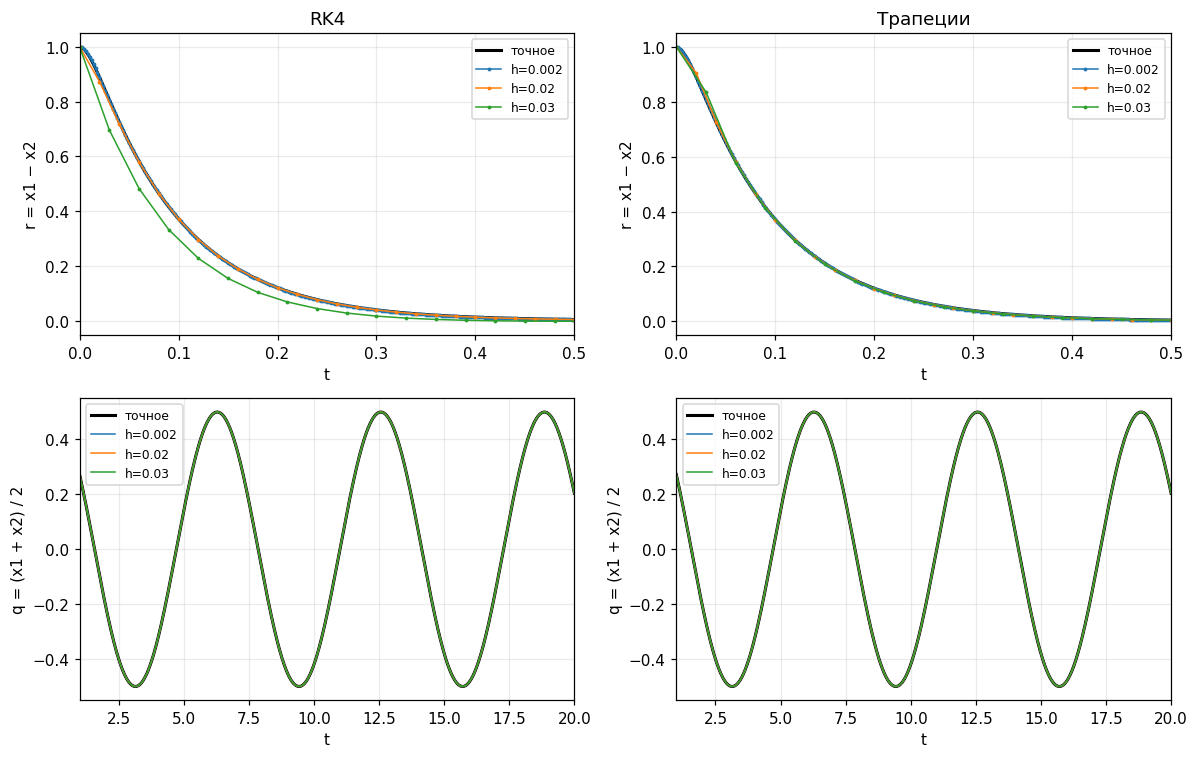

In [4]:
KC, C, T = 499.5, 50.0, 20.0
A = system_matrix(KC, C)
print("Собственные значения:", np.sort_complex(np.linalg.eigvals(A)))
histories = {}
rows = []
for h in [0.002, 0.02, 0.03]:
    times = time_grid(T, h)
    exact = exact_solution(A, Y0, times)
    _, r_exact = modes(exact)
    q_exact = 0.5 * np.cos(times)
    for method in METHODS:
        values, info = integrate(A, Y0, times, method)
        histories[(method, h)] = times, values
        q, r = modes(values)
        rows.append({"Метод": method, "h": h, "max |q−q*|": np.max(abs(q - q_exact)),
                     "max |r−r*|": np.max(abs(r - r_exact)), "Шагов": info["Шагов"]})
display(pd.DataFrame(rows).style.format({"h": "{:.3f}", "max |q−q*|": "{:.3e}",
                                       "max |r−r*|": "{:.3e}"}))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
dense = np.linspace(0, T, 4001)
qd, rd = modes(exact_solution(A, Y0, dense))
for column, method in enumerate(METHODS):
    axes[0, column].plot(dense, rd, color="black", lw=2, label="точное")
    axes[1, column].plot(dense, qd, color="black", lw=2, label="точное")
    for h in [0.002, 0.02, 0.03]:
        times, values = histories[(method, h)]
        q, r = modes(values)
        axes[0, column].plot(times, r, ".-", ms=3, lw=1, label=f"h={h:g}")
        axes[1, column].plot(times, q, lw=1, label=f"h={h:g}")
    axes[0, column].set_xlim(0, 0.5)
    axes[0, column].set_title(method)
    axes[0, column].set_ylabel("r = x1 − x2")
    axes[1, column].set_xlim(1, T)
    axes[1, column].set_ylabel("q = (x1 + x2) / 2")
    for ax in axes[:, column]:
        ax.set_xlabel("t")
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Увеличение шага после переходного процесса

До $t=1$ использую $h=0.002$, затем увеличиваю его до $0.05$. В обоих методах сохраняю полное состояние системы. Для RK4 на отрицательной вещественной оси устойчивость требует $h|\lambda|\lesssim2.7853$, то есть здесь $h\lesssim0.03139$. На новом шаге $h=0.05$ это ограничение нарушено.

В таблице «Последний t» означает последний сохранённый узел. Если норма состояния превышает $10^6$, расчёт останавливается и отмечается как срыв. Ошибку такого расчёта за весь интервал не оцениваю.

,Метод,Срыв,Последний t,max ошибка q до T,Шагов
0,RK4,True,2.20,nan,525
1,Трапеции,False,20.00,1.805e-03,880


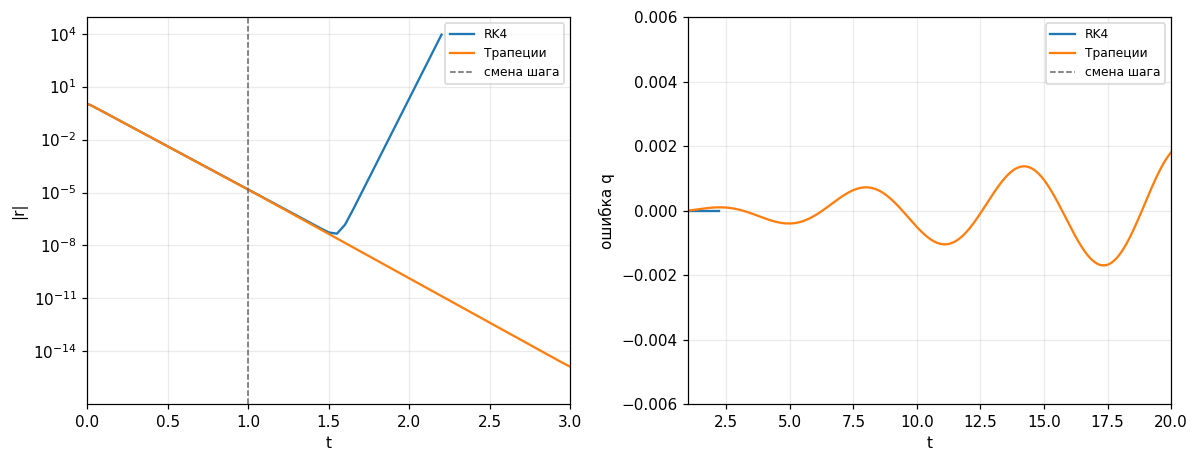

In [5]:
switched_times = np.concatenate([time_grid(1, 0.002), 1 + time_grid(19, 0.05)[1:]])
switched = {}
switch_rows = []
for method in METHODS:
    values, info = integrate(A, Y0, switched_times, method)
    switched[method] = values
    valid = np.isfinite(values).all(axis=1)
    q, r = modes(values)
    slow_error = np.max(abs(q[valid] - 0.5 * np.cos(switched_times[valid])))
    switch_rows.append({"Метод": method, "Срыв": info["Срыв"],
                        "Последний t": switched_times[valid][-1],
                        "max ошибка q до T": np.nan if info["Срыв"] else slow_error,
                        "Шагов": info["Шагов"]})
display(pd.DataFrame(switch_rows).style.format({"Последний t": "{:.2f}",
                                               "max ошибка q до T": "{:.3e}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for method, values in switched.items():
    q, r = modes(values)
    axes[0].semilogy(switched_times, np.maximum(abs(r), 1e-16), label=method)
    axes[1].plot(switched_times, q - 0.5 * np.cos(switched_times), label=method)
axes[0].set_xlim(0, 3)
axes[0].set_ylabel("|r|")
axes[1].set_xlim(1, T)
axes[1].set_ylim(-0.006, 0.006)
axes[1].set_ylabel("ошибка q")
for ax in axes:
    ax.axvline(1, color="0.4", ls="--", lw=1, label="смена шага")
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Анимации

Положения равновесия масс на рисунке равны 2 и 5. Показанное положение груза — положение равновесия плюс $0.55x_i$. Масштаб смещения одинаков для обеих масс. Пружины и демпфер нарисованы схематично.

Первая анимация показывает целый цикл биений за $T=130$. Её экранное время ускорено примерно в 13 раз. Для этого визуального ряда использую точное решение, проверенное выше сравнением с RK4. Вторая анимация использует метод трапеций с $h=0.002$ и показывает $T=8$ с графиком $r(t)$ и движущимся маркером времени. Первые кадры дополнительно разрешают быстрый переходный процесс, поэтому масштаб времени при воспроизведении меняется. GIF встроены в ноутбук.

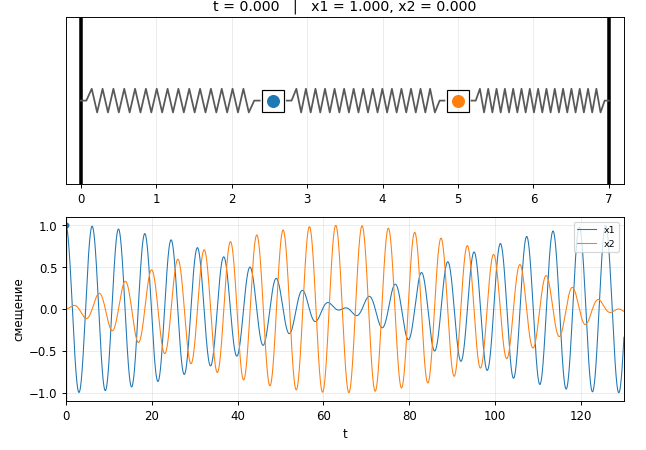

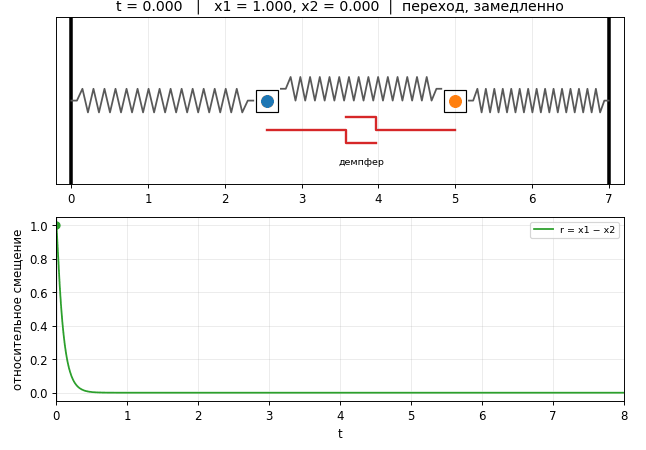

In [6]:
def spring(ax, left, right, y=0.0, color="0.35", label=None):
    xs = np.linspace(left, right, 34)
    ys = np.zeros_like(xs) + y
    ys[2:-2] += 0.12 * (-1.0)**np.arange(len(xs) - 4)
    ax.plot(xs, ys, color=color, lw=1.5, label=label)


def animate_system(times, values, frame_indices, damping=False, fps=12):
    fig, (ax, graph) = plt.subplots(2, 1, figsize=(7.6, 5.3),
                                    gridspec_kw={"height_ratios": [1, 1.1]})
    q, r = modes(values)
    if damping:
        graph.plot(times, r, color="C2", label="r = x1 − x2")
        marker, = graph.plot([], [], "o", color="C2")
        graph.set_ylabel("относительное смещение")
    else:
        graph.plot(times, values[:, 0], color="C0", lw=0.9, label="x1")
        graph.plot(times, values[:, 1], color="C1", lw=0.9, label="x2")
        marker, = graph.plot([], [], "o", color="C0", ms=4)
        graph.set_ylabel("смещение")
    cursor = graph.axvline(0, color="black", lw=1)
    graph.set_xlim(times[0], times[-1])
    graph.set_xlabel("t")
    graph.legend(loc="upper right", fontsize=8)
    fig.tight_layout()

    with TemporaryDirectory() as directory:
        path = Path(directory) / "motion.gif"
        writer = PillowWriter(fps=fps)
        with writer.saving(fig, path, dpi=85):
            for index in frame_indices:
                ax.clear()
                positions = np.array([2.0, 5.0]) + 0.55 * values[index, :2]
                p1, p2 = positions
                ax.axvline(0, color="black", lw=3)
                ax.axvline(7, color="black", lw=3)
                spring(ax, 0, p1 - 0.18)
                spring(ax, p2 + 0.18, 7)
                spring(ax, p1 + 0.18, p2 - 0.18, y=0.12 if damping else 0)
                if damping:
                    left = (p1 + p2) / 2 - 0.2
                    right = left + 0.4
                    ax.plot([p1, left, left, right], [-0.3, -0.3, -0.43, -0.43],
                            color="C3", lw=2)
                    ax.plot([left, right, right, p2], [-0.17, -0.17, -0.3, -0.3],
                            color="C3", lw=2)
                    ax.text((p1 + p2) / 2, -0.65, "демпфер", ha="center", fontsize=8)
                ax.plot(positions, [0, 0], "s", ms=18, mfc="none", mec="black")
                ax.plot(p1, 0, "o", ms=10, color="C0")
                ax.plot(p2, 0, "o", ms=10, color="C1")
                ax.set_xlim(-0.2, 7.2)
                ax.set_ylim(-0.85, 0.85)
                ax.set_yticks([])
                phase = "переход, замедленно" if times[index] <= 0.5 else "последующее движение"
                time_note = f"  |  {phase}" if damping else ""
                ax.set_title(f"t = {times[index]:.3f}   |   x1 = {values[index, 0]:.3f}, "
                             f"x2 = {values[index, 1]:.3f}" + time_note)
                cursor.set_xdata([times[index], times[index]])
                marker.set_data([times[index]], [r[index] if damping else values[index, 0]])
                writer.grab_frame()
        result = Image(data=path.read_bytes(), format="gif", width=700)
    plt.close(fig)
    display(result)


# Точная кривая для анимации биений, 121 кадр за полный интервал.
weak_frames = np.linspace(0, len(t_weak) - 1, 121, dtype=int)
animate_system(t_weak, weak_exact, weak_frames)

# Начальный переход показывается чаще, чем последующее медленное движение.
strong_times = time_grid(8, 0.002)
strong_values, _ = integrate(A, Y0, strong_times, "Трапеции")
frame_times = np.unique(np.r_[np.linspace(0, 0.5, 25), np.linspace(0.5, 8, 91)])
frame_indices = np.searchsorted(strong_times, frame_times)
animate_system(strong_times, strong_values, frame_indices, damping=True)

## 7. Ответ на вопрос

**Можно ли после затухания быстрого процесса увеличить шаг, сохранив устойчивость и точность медленного движения?**

Для метода трапеций в выбранном опыте это возможно. Смена шага с $0.002$ на $0.05$ после $t=1$ сохраняет устойчивость, а ошибка $q$ до $T=20$ остаётся меньше $0.003$. Здесь быстрые компоненты к моменту смены шага уже малы, и новый шаг достаточно хорошо разрешает период совместных колебаний $2\pi$.

Для RK4 ограничение устойчивости полного оператора сохраняется и после затухания относительного движения. Шаг $0.05$ превышает порог около $0.03139$. Остаточная быстрая компонента усиливается, и расчёт срывается. Полное исчезновение этой компоненты в точной арифметике было бы особым случаем. В данном опыте её остаток присутствует и доходит до неустойчивого режима.

Даже у безусловно устойчивого метода шаг ограничивается точностью медленного движения. У трапеций при $\omega=1$ численная частота равна $2\arctan(h/2)/h$. На большом интервале фазовая ошибка накапливается. Поэтому возможность увеличить шаг проверяю по ошибке совместной моды, а переходный процесс — по относительному смещению.